In [1]:
import glob
import os

from matplotlib import font_manager as fm
import matplotlib as mpl

font_dir = os.path.expanduser("~/.local/share/fonts")
for path in glob.glob(os.path.join(font_dir, "lm*.otf")):
    fm.fontManager.addfont(path)
for path in glob.glob(os.path.join(font_dir, "cmu*.otf")):
    fm.fontManager.addfont(path)

mpl.rcParams.update({
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,

    "font.family": "serif",

    "font.serif": ["LMRoman10", "CMU Serif", "DejaVu Serif"],
    "font.sans-serif": ["LMSans10", "CMU Sans Serif", "DejaVu Sans"],
    "font.monospace": ["LMMono10", "CMU Typewriter Text", "DejaVu Sans Mono"],
})


ERROR 1: PROJ: proj_create_from_database: Open of /home/jpalmo/.conda/envs/earthdata/share/proj failed


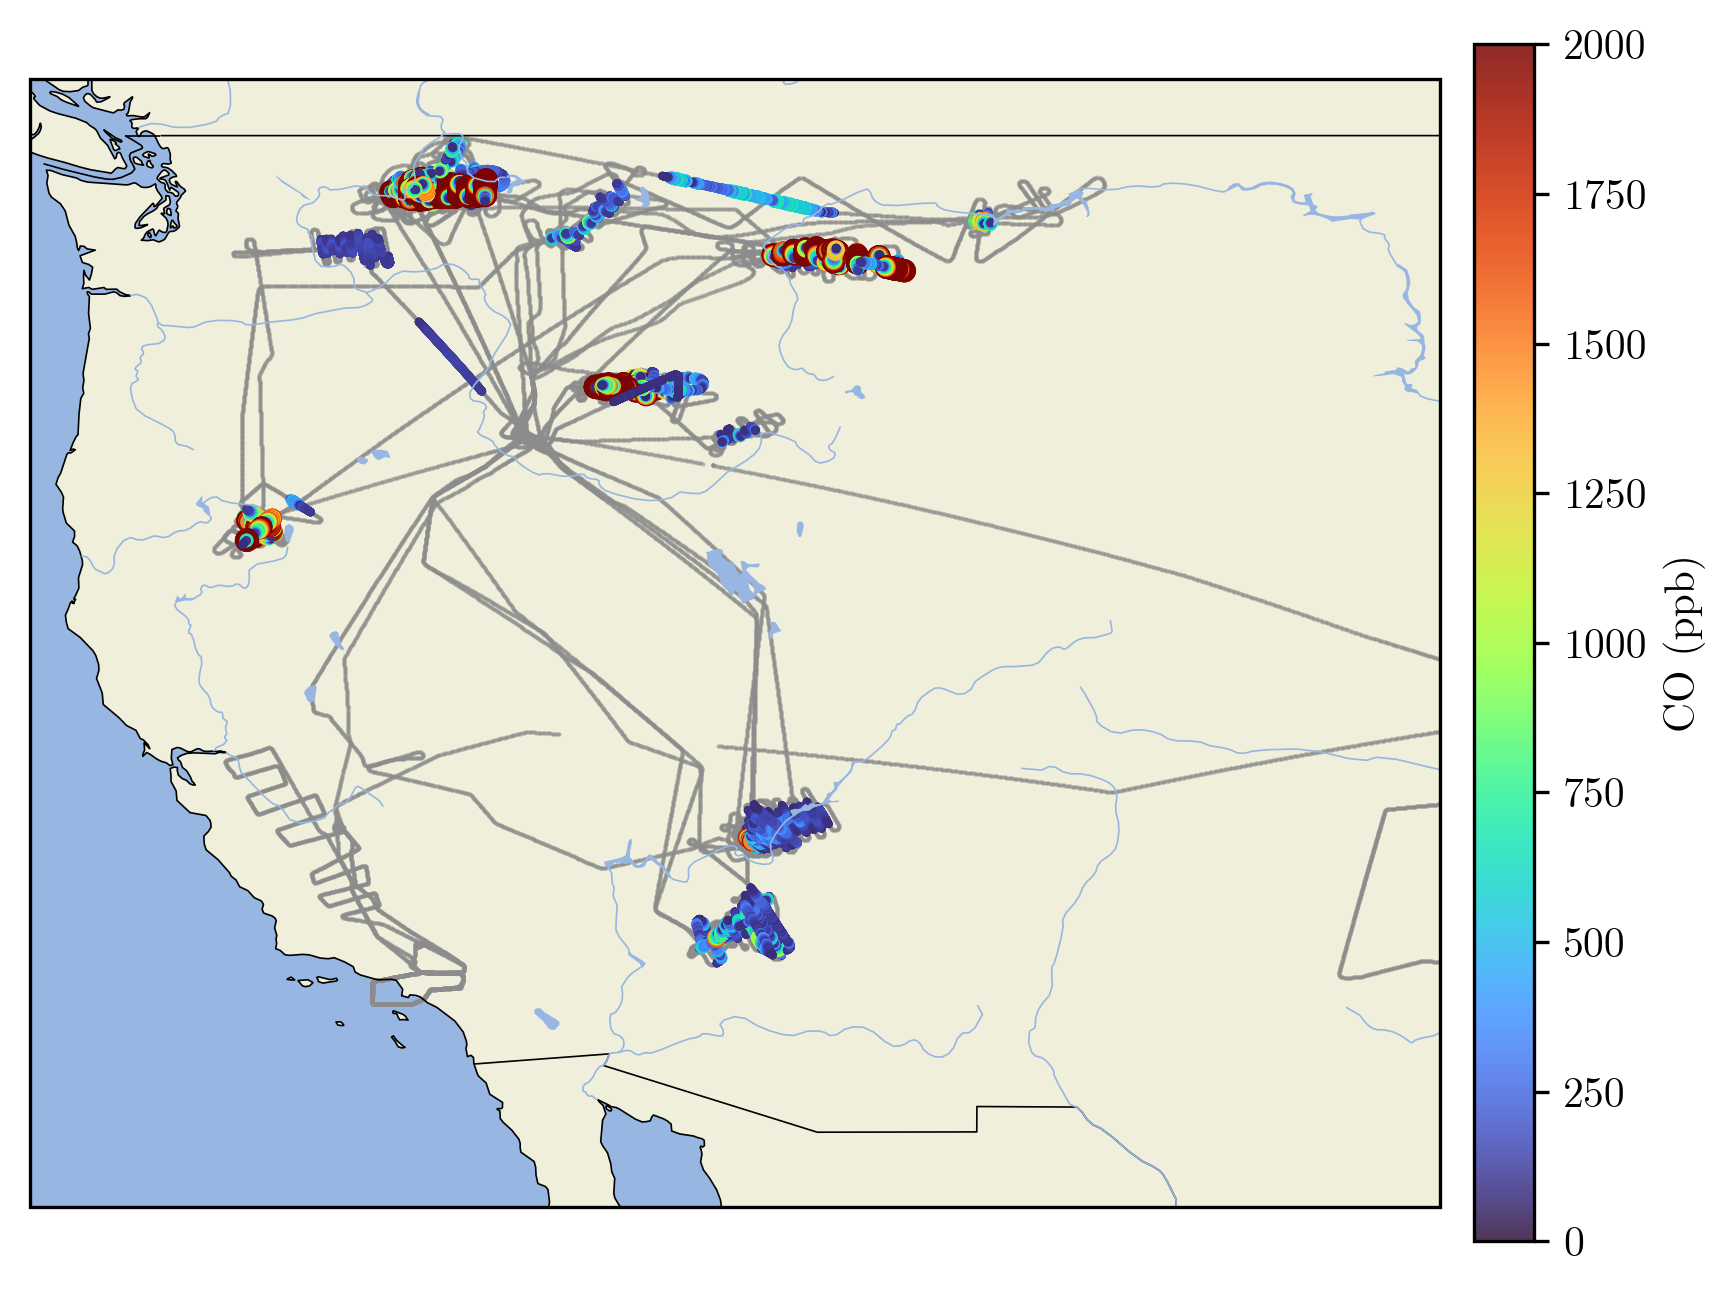

In [2]:
%matplotlib inline

from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

MERGE = Path("/home/jpalmo/fs09/Projects/TROPOMI_fire/airborne/mrg01_cleaned.csv")
df = pd.read_csv(MERGE, usecols=["Longitude", "Latitude", "CO_DACOM", "Smoke_flag", "transect_number"])
plume = (df["Smoke_flag"] == 1) & (df["transect_number"] > 0) & np.isfinite(df["CO_DACOM"])
track = ~plume

fig, ax = plt.subplots(figsize=(6, 6), subplot_kw={"projection": ccrs.PlateCarree()}, dpi=300)
ax.set_extent([-125, -100, 30, 50], crs=ccrs.PlateCarree())
for feature in (cfeature.LAND, cfeature.OCEAN, cfeature.COASTLINE, cfeature.BORDERS, cfeature.LAKES, cfeature.RIVERS):
    ax.add_feature(feature, linewidth=0.4)

track_xy = df.loc[track, ["Longitude", "Latitude"]].iloc[::8]
ax.scatter(
    track_xy["Longitude"], track_xy["Latitude"],
    s=1, c="0.55", alpha=0.5, transform=ccrs.PlateCarree(), linewidths=0, rasterized=True, label="Track",
)

co = df.loc[plume, "CO_DACOM"].to_numpy()
lo, hi = np.nanpercentile(co, [5, 95])
sizes = 4 + (np.clip(co, lo, hi) - lo) / (hi - lo + 1e-12) * 28
sc = ax.scatter(
    df.loc[plume, "Longitude"], df.loc[plume, "Latitude"],
    c=co, s=sizes, cmap="turbo", vmin=0, vmax=2000,
    alpha=0.85, transform=ccrs.PlateCarree(), linewidths=0, rasterized=True,
)
bar = fig.colorbar(sc, ax=ax, shrink=0.7, pad=0.02)
bar.set_label("CO (ppb)")
fig.tight_layout()
png_path = "/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/figs/pngs/figs01.png"
plt.savefig(png_path, dpi=300)
pdf_path = "/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/figs/pdfs/figs01.pdf"
plt.savefig(pdf_path, dpi=300)
plt.show()
